# Group 9 — SMS Robustness Testing
Supplementary exploratory experiment (not the primary held-out benchmark). Use the saved models from SMS_Classification_Testing.ipynb. Run that notebook's save section first and make its `group9_saved_models` folder available in this runtime. No retraining here. AI assistance: ChatGPT helped draft this notebook and example messages; review, execute and interpret the results yourself.

In [6]:
%pip install -q joblib scikit-learn sentence-transformers "transformers>=4.44,<5" pandas matplotlib

In [7]:

from google.colab import drive
drive.mount('/content/drive')

import shutil

shutil.copytree(
    '/content/drive/MyDrive/group9_saved_models',
    '/content/group9_saved_models',
    dirs_exist_ok=True
)

print("Models loaded successfully!")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Models loaded successfully!


In [8]:
from pathlib import Path
import joblib, torch, pandas as pd, numpy as np
from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score
import matplotlib.pyplot as plt
from datetime import datetime, timezone
from IPython.display import display
root = Path('/content/group9_saved_models')
assert root.exists(), 'Copy the saved group9_saved_models folder into /content first.'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
tfidf = joblib.load(root/'tfidf_pipeline.joblib')
lr = joblib.load(root/'minilm_logreg.joblib')
enc = SentenceTransformer(str(root/'minilm_encoder'), device=device)
tok = AutoTokenizer.from_pretrained(root/'distilbert')
bert = AutoModelForSequenceClassification.from_pretrained(root/'distilbert').to(device).eval()
def predict_bert(texts):
    out = []
    with torch.inference_mode():
        for i in range(0,len(texts),32):
            batch = tok(texts[i:i+32], padding=True, truncation=True, max_length=128, return_tensors='pt').to(device)
            out.extend(bert(**batch).logits.argmax(-1).cpu().tolist())
    return out

## Test messages
AI-drafted examples below are synthetic, not UCI held-out samples. Replace at least one ham and one spam with your own original messages, then review all labels before running. Keep the classes balanced.

In [9]:

examples = [
(1,'Congratulations your number was selected to receive a free laptop'),
(1,'You won a cash reward today'),
(1,'Send your bank details to claim your bonus'),
(1,'Your free voucher is waiting for you'),
(1,'Text us now to receive your prize'),
(1,'Claim your exclusive reward before midnight'),
(1,'You have been selected for a free gift'),
(1,'Pay a small fee to unlock your winnings'),
(1,'Verify your card to receive your cash prize'),
(1,'Reply now for your guaranteed free phone'),
(0,'Lets meet at the university library after our NLP lecture'),
(0,'I will send you the class notes now'),
(0,'Can you bring your book tomorrow'),
(0,'Your lunch is ready for you'),
(0,'Text me when you get home'),
(0,'I left your keys on the table'),
(0,'We can meet after class today'),
(0,'Please call me when you are free'),
(0,'I bought a gift for your sister'),
(0,'Can you pick me up tomorrow')]

assert len(examples)==20 and sum(y for y,t in examples)==10


In [10]:
import re
def typo(s):
    return re.sub(r'\b([A-Za-z]{4,})\b',lambda m:m[0][:2]+m[0][1]+m[0][2:],s,count=1)
def shorthand(s):
    mapping={'you':'u','your':'ur','today':'2day','tomorrow':'2moro','now':'rn','to':'2','for':'4','me':'me','are':'r'}
    return re.sub(r'\b\w+\b',lambda m:mapping.get(m[0].lower(),m[0]),s)
variants={'Original':lambda s:s,'Misspelling':typo,'Obfuscation':lambda s:s.translate(str.maketrans('aeioAEIO','43104310')),'Uppercase':str.upper,'Extra spaces':lambda s:s.replace(' ','   '),'Text-speak':shorthand}
rows=[]
for i,(label,msg) in enumerate(examples):
    for kind,fn in variants.items():
        changed=fn(msg)
        rows.append({'id':i,'label':label,'variant':kind,'text':changed,'changed':changed!=msg})
data=pd.DataFrame(rows)
display(data.head(12))
print('Cases:',len(data))
print('Actually changed per variant:')
print(data.groupby('variant').changed.sum())

,id,label,variant,text,changed
0,0,1,Original,Congratulations your number was selected to re...,False
1,0,1,Misspelling,Coongratulations your number was selected to r...,True
2,0,1,Obfuscation,C0ngr4tul4t10ns y0ur numb3r w4s s3l3ct3d t0 r3...,True
3,0,1,Uppercase,CONGRATULATIONS YOUR NUMBER WAS SELECTED TO RE...,True
4,0,1,Extra spaces,Congratulations your number was select...,True
5,0,1,Text-speak,Congratulations ur number was selected 2 recei...,True
6,1,1,Original,You won a cash reward today,False
7,1,1,Misspelling,You won a caash reward today,True
8,1,1,Obfuscation,Y0u w0n 4 c4sh r3w4rd t0d4y,True
9,1,1,Uppercase,YOU WON A CASH REWARD TODAY,True


Cases: 120
Actually changed per variant:
variant
Extra spaces    20
Misspelling     20
Obfuscation     20
Original         0
Text-speak      19
Uppercase       20
Name: changed, dtype: int64


In [11]:
texts=data.text.tolist()
models={'TF-IDF':tfidf.predict(texts),'MiniLM':lr.predict(enc.encode(texts,batch_size=32,show_progress_bar=False)),'DistilBERT':predict_bert(texts)}
records=[]
for name,p in models.items():
    for row,pred in zip(data.to_dict('records'),p):
        records.append({**row,'model':name,'prediction':int(pred),'correct':int(pred)==row['label']})
results=pd.DataFrame(records)
summary=pd.DataFrame([{'model':name,'variant':kind,'n':len(g),'accuracy':accuracy_score(g.label,g.prediction),'macro_f1':f1_score(g.label,g.prediction,labels=[0,1],average='macro',zero_division=0)} for (name,kind),g in results.groupby(['model','variant'])])
base=summary[summary.variant=='Original'].set_index('model').accuracy
summary['accuracy_drop_pp']=(summary.model.map(base)-summary.accuracy)*100
display(summary.round(3))

,model,variant,n,accuracy,macro_f1,accuracy_drop_pp
0,DistilBERT,Extra spaces,20,0.85,0.847,0.0
1,DistilBERT,Misspelling,20,0.65,0.601,20.0
2,DistilBERT,Obfuscation,20,0.50,0.333,35.0
3,DistilBERT,Original,20,0.85,0.847,0.0
4,DistilBERT,Text-speak,20,0.80,0.792,5.0
5,DistilBERT,Uppercase,20,0.85,0.847,0.0
6,MiniLM,Extra spaces,20,0.90,0.900,0.0
7,MiniLM,Misspelling,20,0.80,0.798,10.0
8,MiniLM,Obfuscation,20,0.40,0.400,50.0
9,MiniLM,Original,20,0.90,0.900,0.0


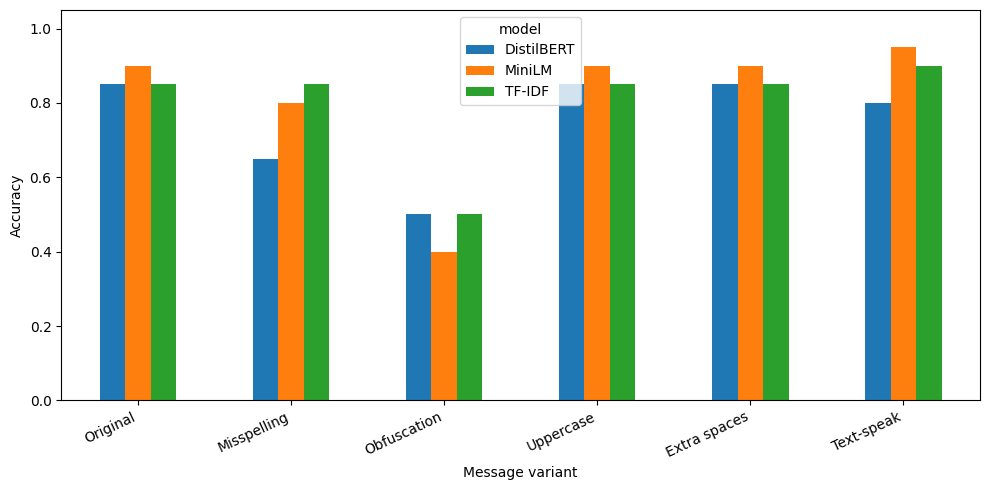

,model,id,variant,text,label,prediction
2,TF-IDF,0,Obfuscation,C0ngr4tul4t10ns y0ur numb3r w4s s3l3ct3d t0 r3...,1,0
7,TF-IDF,1,Misspelling,You won a caash reward today,1,0
8,TF-IDF,1,Obfuscation,Y0u w0n 4 c4sh r3w4rd t0d4y,1,0
14,TF-IDF,2,Obfuscation,S3nd y0ur b4nk d3t41ls t0 cl41m y0ur b0nus,1,0
20,TF-IDF,3,Obfuscation,Y0ur fr33 v0uch3r 1s w41t1ng f0r y0u,1,0
26,TF-IDF,4,Obfuscation,T3xt us n0w t0 r3c31v3 y0ur pr1z3,1,0
31,TF-IDF,5,Misspelling,Cllaim your exclusive reward before midnight,1,0
32,TF-IDF,5,Obfuscation,Cl41m y0ur 3xclus1v3 r3w4rd b3f0r3 m1dn1ght,1,0
38,TF-IDF,6,Obfuscation,Y0u h4v3 b33n s3l3ct3d f0r 4 fr33 g1ft,1,0
50,TF-IDF,8,Obfuscation,V3r1fy y0ur c4rd t0 r3c31v3 y0ur c4sh pr1z3,1,0


Execution UTC: 2026-11-26T21:31:09.266687+00:00


In [12]:
ax=summary.pivot(index='variant',columns='model',values='accuracy').reindex(list(variants)).plot.bar(figsize=(10,5))
ax.set_ylabel('Accuracy'); ax.set_ylim(0,1.05); ax.set_xlabel('Message variant')
plt.xticks(rotation=25,ha='right'); plt.tight_layout(); plt.savefig('robustness_accuracy.png',dpi=180); plt.show()
original=results[results.variant=='Original'][['model','id','correct']].rename(columns={'correct':'original_correct'})
flips=results.merge(original,on=['model','id'])
display(flips[(flips.variant!='Original') & flips.original_correct & ~flips.correct][['model','id','variant','text','label','prediction']])
results.to_csv('robustness_predictions.csv',index=False)
summary.to_csv('robustness_summary.csv',index=False)
print('Execution UTC:',datetime.now(timezone.utc).isoformat())

## Your interpretation (complete after execution)
- Which model had the highest original accuracy?
- Which perturbation caused the largest accuracy drop for each model?
- Explain two actual errors using the output above.
- Limitations: small synthetic balanced sample; variants are paired, not independent; some transformations may leave messages unchanged; results do not establish general robustness or replace the main held-out benchmark.
- Record your actual execution date and commit the notebook with outputs and CSV files.